<a href="https://colab.research.google.com/github/Sanika515/AIML/blob/main/10%09Music_Genre_Classification_using_RNN_%5BDataset_GTZAN_Music_Genre_Dataset_%5D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install kagglehub librosa
import kagglehub
path = kagglehub.dataset_download('andradaolteanu/gtzan-dataset-music-genre-classification')
print(path)

Using Colab cache for faster access to the 'gtzan-dataset-music-genre-classification' dataset.
/kaggle/input/gtzan-dataset-music-genre-classification


In [ ]:
import os, glob, numpy as np, matplotlib.pyplot as plt, librosa
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# 1. locate the audio folder  (Data/genres_original/<genre>/<genre>.000xx.wav)
audio_root = None
for r, d, f in os.walk(path):
    if os.path.basename(r) == 'genres_original':
        audio_root = r; break
genres = sorted(os.listdir(audio_root))
print(genres)

SR, SEG_SEC, N_MFCC, HOP = 22050, 3, 20, 1024
FILES_PER_GENRE = 100          # use 30 for a quick test run

files, labels = [], []
for gi, g in enumerate(genres):
    fl = sorted(glob.glob(f'{audio_root}/{g}/*.wav'))[:FILES_PER_GENRE]
    files += fl; labels += [gi] * len(fl)

# 2. split by SONG (so pieces of the same song never appear in both train and test)
f_tr, f_te, l_tr, l_te = train_test_split(files, labels, test_size=0.2, stratify=labels, random_state=42)
print("train songs:", len(f_tr), " test songs:", len(f_te))

['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']
train songs: 800  test songs: 200


In [ ]:
# 3. Feature extraction: each song -> ten 3-second pieces -> MFCC matrix (65 time steps x 20 coefficients)
def extract(file_list, label_list):
    X, y = [], []
    n = SR * SEG_SEC
    for f, l in zip(file_list, label_list):
        try:
            sig, _ = librosa.load(f, sr=SR, duration=30)
        except Exception as e:                       # GTZAN has one corrupted file (jazz.00054)
            print("skipped:", os.path.basename(f)); continue
        for s in range(len(sig) // n):
            seg = sig[s * n:(s + 1) * n]
            mfcc = librosa.feature.mfcc(y=seg, sr=SR, n_mfcc=N_MFCC, hop_length=HOP).T     # (time, n_mfcc)
            X.append(mfcc); y.append(l)
    return np.array(X), np.array(y)

X_tr, y_tr = extract(f_tr, l_tr)
X_te, y_te = extract(f_te, l_te)
print("X_train:", X_tr.shape, " X_test:", X_te.shape)

# 4. normalise using training statistics
mu, sd = X_tr.mean(axis=(0, 1)), X_tr.std(axis=(0, 1)) + 1e-8
X_tr, X_te = (X_tr - mu) / sd, (X_te - mu) / sd

/tmp/ipykernel_417/809525790.py:7: UserWarning: PySoundFile failed. Trying audioread instead.
  sig, _ = librosa.load(f, sr=SR, duration=30)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


skipped: jazz.00054.wav
X_train: (7981, 65, 20)  X_test: (2000, 65, 20)


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# 5. RNN model
model = keras.Sequential([
    layers.Input(shape=X_tr.shape[1:]),                       # (65 time steps, 20 MFCCs)
    layers.SimpleRNN(128, return_sequences=True),
    layers.Dropout(0.3),
    layers.SimpleRNN(64),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dense(len(genres), activation='softmax')
])
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

early = keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=8, restore_best_weights=True)
history = model.fit(X_tr, y_tr, validation_split=0.1, epochs=40, batch_size=64, callbacks=[early])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 65, 128)        │        19,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 65, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 36,234 (141.54 KB)

 Trainable params: 36,234 (141.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
113/113 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - accuracy: 0.3312 - loss: 1.8967 - val_accuracy: 0.4643 - val_loss: 1.6073
Epoch 2/40
113/113 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.4248 - loss: 1.6049 - val_accuracy: 0.4743 - val_loss: 1.5058
Epoch 3/40
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - accuracy: 0.4630 - loss: 1.5226 - val_accuracy: 0.5194 - val_loss: 1.4573
Epoch 4/40
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.4886 - loss: 1.4825 - val_accuracy: 0.4856 - val_loss: 1.5095
Epoch 5/40
113/113 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.5011 - loss: 1.4357 - val_accuracy: 0.4906 - val_loss: 1.5070
Epoch 6/40
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - accuracy: 0.5223 - loss: 1.3909 - val_accuracy: 0.5244 - val_loss: 1.4360
Epoch 7/40
113/113 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - accuracy: 0.5309 - loss: 1.3699 - val_accuracy: 0.5457 - val_loss: 1.3920
Epoch 8/40
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - accuracy: 0.5532 - loss: 1.3016 - val_accu

Test accuracy (3-second pieces): 51.30%
              precision    recall  f1-score   support

       blues       0.40      0.51      0.45       200
   classical       0.77      0.90      0.83       200
     country       0.42      0.18      0.25       200
       disco       0.37      0.20      0.26       200
      hiphop       0.41      0.38      0.40       200
        jazz       0.51      0.69      0.58       200
       metal       0.62      0.64      0.63       200
         pop       0.57      0.83      0.67       200
      reggae       0.47      0.47      0.47       200
        rock       0.41      0.34      0.37       200

    accuracy                           0.51      2000
   macro avg       0.49      0.51      0.49      2000
weighted avg       0.49      0.51      0.49      2000



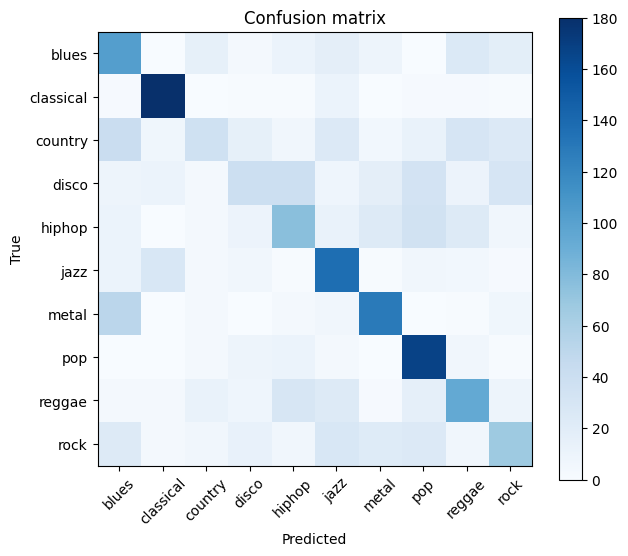

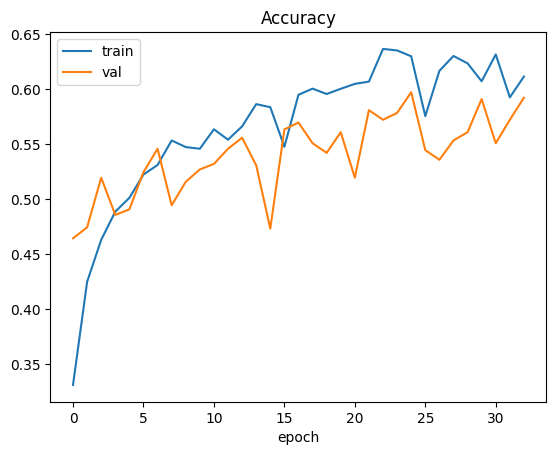

Song: classical.00071.wav | Predicted: classical | True: classical


In [ ]:
# 6. Evaluate on unseen songs
loss, acc = model.evaluate(X_te, y_te, verbose=0)
print(f"Test accuracy (3-second pieces): {acc*100:.2f}%")

y_pred = np.argmax(model.predict(X_te, verbose=0), axis=1)
print(classification_report(y_te, y_pred, target_names=genres))

cm = confusion_matrix(y_te, y_pred)
plt.figure(figsize=(7, 6)); plt.imshow(cm, cmap='Blues'); plt.colorbar()
plt.xticks(range(10), genres, rotation=45); plt.yticks(range(10), genres)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion matrix'); plt.show()

plt.plot(history.history['accuracy'], label='train'); plt.plot(history.history['val_accuracy'], label='val')
plt.legend(); plt.title('Accuracy'); plt.xlabel('epoch'); plt.show()

# predict genre of one test song = majority vote over its 3-second pieces
i = 0
song = f_te[i]
sig, _ = librosa.load(song, sr=SR, duration=30)
n = SR * SEG_SEC
pieces = np.array([librosa.feature.mfcc(y=sig[s*n:(s+1)*n], sr=SR, n_mfcc=N_MFCC, hop_length=HOP).T for s in range(len(sig)//n)])
votes = np.argmax(model.predict((pieces - mu) / sd, verbose=0), axis=1)
print("Song:", os.path.basename(song), "| Predicted:", genres[np.bincount(votes).argmax()], "| True:", genres[l_te[i]])

In [ ]:
1. What is the problem?

Given a music clip, the computer must say its genre: blues, classical, country, disco, hiphop, jazz, metal, pop, reggae or rock (10 genres).

2. The dataset: GTZAN
1,000 songs: 10 genres × 100 songs each.
Each song is 30 seconds long, saved as a .wav audio file.
It is the standard benchmark dataset for music genre classification.
One known problem: the file jazz.00054.wav is corrupted. The code skips it with a try/except.
3. What is the solution?

A neural network can't read a sound file directly. We do three things:

Step A: Cut each song into pieces. Each 30-second song is cut into ten 3-second pieces. This gives us 10× more training samples (about 10,000) and shorter sequences, which are easier for an RNN.

Step B: Turn each piece into numbers (MFCC). An MFCC (Mel-Frequency Cepstral Coefficients) is a compact description of the sound's tone and texture, measured the way the human ear hears. For each short moment of audio (one "frame") we get 20 numbers. A 3-second piece gives 65 frames × 20 numbers.

Analogy: think of a picture of a sound, where one axis is time and the other is "what the sound is like at that moment".

Step C: Feed the sequence to an RNN. An RNN reads sequences, one step at a time, and keeps a memory. Here the 65 frames are the 65 time steps, and each step has 20 features. The RNN reads frame 1, then frame 2, and so on, and its final memory summarises the clip.

"Music is a sequence in time. An RNN reads the MFCC frames one after another and remembers what it heard, so it can decide the genre."
###############CODE################

Step 1: Download and find the audio

python
path = kagglehub.dataset_download('andradaolteanu/gtzan-dataset-music-genre-classification')
# find the folder genres_original -> one sub-folder per genre
genres = sorted(os.listdir(audio_root))

Step 2: Settings

python
SR, SEG_SEC, N_MFCC, HOP = 22050, 3, 20, 1024
FILES_PER_GENRE = 100
SR = 22050: samples per second of audio.
SEG_SEC = 3: the length of each piece.
N_MFCC = 20: 20 numbers for each frame.
HOP = 1024: the step between frames (about 46 ms). 3 seconds ÷ 46 ms ≈ 65 frames.
FILES_PER_GENRE: use 100 for the full dataset. Use 30 for a quick test.

Step 3: Split by song, not by piece

python
f_tr, f_te, l_tr, l_te = train_test_split(files, labels, test_size=0.2, stratify=labels, random_state=42)

We split the songs 80/20 before cutting them into pieces. If we split pieces randomly, pieces of the same song would land in both training and test sets. The model would then "recognise" the song instead of the genre, and the accuracy would be falsely high. This is called data leakage, and this split avoids it. stratify keeps all genres equally represented.

Step 4: Extract features

python
sig, _ = librosa.load(f, sr=SR, duration=30)
seg = sig[s*n:(s+1)*n]
mfcc = librosa.feature.mfcc(y=seg, sr=SR, n_mfcc=N_MFCC, hop_length=HOP).T
librosa is the audio library. It loads the song, and we cut it into 3-second pieces.
.T flips the matrix so its shape is (time, features) = (65, 20), which is what an RNN needs.
This is the slow step, taking several minutes.

Step 5: Normalise

python
mu, sd = X_tr.mean(axis=(0,1)), X_tr.std(axis=(0,1)) + 1e-8
X_tr, X_te = (X_tr - mu) / sd, (X_te - mu) / sd

We rescale every feature to a standard range, using the training statistics only. This makes training faster and more stable.

Step 6: Build the model (the table above).

Step 7: Train

python
early = keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=8, restore_best_weights=True)
history = model.fit(X_tr, y_tr, validation_split=0.1, epochs=40, batch_size=64, callbacks=[early])

EarlyStopping stops training when validation accuracy hasn't improved for 8 epochs, and goes back to the best weights. It prevents overfitting and saves time.

Step 8: Evaluate

Test accuracy, a classification report and a confusion matrix.
Final cell: it predicts one whole song by majority vote. All ten pieces of the song are classified, and the genre predicted most often wins.
5. The output you will see
A list of the 10 genres.
train songs: 800 test songs: 200.
Possibly skipped: jazz.00054.wav, which is expected.
X_train: (~8000, 65, 20) X_test: (~2000, 65, 20).
The model summary with about 36,000 parameters in the two RNNs plus the Dense layers.
A training log. In your screenshot, training accuracy was about 60–63% and validation accuracy about 52–59%, with loss around 1.1. The log stops around epoch 33–40.
Test accuracy of roughly 50–60% for the RNN (random guessing would be 10%).
A classification report. Classical, jazz and metal usually score best, and rock, country and blues usually score worst, because they sound alike.
A confusion matrix and an accuracy graph.
The last line: the song name, the predicted genre and the true genre.
6. Why is the accuracy only 50–60%? (very likely viva question)

Your result is correct and normal:

A SimpleRNN has weak memory. It suffers from the vanishing gradient problem: when learning across 65 time steps, the gradients shrink, so it forgets earlier frames.
Each clip is only 3 seconds, so some genres (rock, country, blues) sound alike.
The next program uses an LSTM, which should do better on the same data.

"The RNN reaches about 55% because a simple RNN suffers from vanishing gradients and can't remember long sequences well. The LSTM in Program 11 solves this."


################BLOCK#################
          START
            |
            v
       Load GTZAN Dataset
            |
            v
        Load Audio Files
             (.wav)
            |
            v
        Split Songs
        Train / Test
            |
            v
       Audio Preprocessing
        (22050 Hz)
            |
            v
       Divide into 3-sec
          Segments
            |
            v
       Extract MFCC Features
         (20 Coefficients)
            |
            v
        Normalize Features
            |
            v
         Build RNN Model
            |
            v
       SimpleRNN (128)
            |
            v
          Dropout
            |
            v
        SimpleRNN (64)
            |
            v
          Dropout
            |
            v
        Dense + Softmax
            |
            v
         Train Model
            |
            v
        Evaluate Model
            |
            v
       Predict Music Genre
            |
            v
           STOP

##################QUE#########
Why use an RNN for music? Music is a sequence in time. An RNN reads frames in order and keeps a memory.
What is MFCC? Mel-Frequency Cepstral Coefficients: features of the sound spectrum on the mel scale (how humans hear), compressed into a few numbers. They capture the timbre.
Why cut songs into 3-second pieces? It gives 10× more training samples and shorter sequences (65 steps instead of about 1300), which are easier for an RNN.
Why split by song? To avoid data leakage. Pieces of the same song sound alike, so a random piece split would give falsely high accuracy.
What does return_sequences=True do? It outputs the hidden state at every time step instead of only the last one, so another recurrent layer can be stacked on top.
What is EarlyStopping? It stops training when validation accuracy stops improving and restores the best weights.
What are sampling rate and hop length? The sampling rate (22,050 Hz) is how many audio samples are taken per second. The hop length (1024) is the gap between two successive MFCC frames.
Why normalise the MFCCs? The coefficients have different scales, and standardising them makes training faster and more stable.
Other approaches to genre classification? CNN on spectrogram images, CRNN (CNN + RNN), transfer learning with audio models, or classical ML such as SVM.